# COU 07506 Digital Signal Processing — Week 03: Lab 1B — Convolution, Correlation and Difference Equations

- **Name:** Faida Sylvester Mosses
- **Registration No.:** 240647474625
- **Class:** BEng24ETE (Stream 2)
- **Group:** 09
- **Date:** 25 November 2026
- **Instructor checkpoints signed:** [ ] 1  [ ] 2

### Setup — standard imports (Lab 1B)
Load the libraries used in this lab.

In [1]:
# Lab 1B - Setup: standard imports
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
plt.rcParams["figure.figsize"] = (9, 3.5)

### Pre-lab (Lab 1B)

**(a)** Convolve x(n) = {1, −1, 2} with h(n) = {2, 1, 0, 1} by hand.

Using y(n) = Σ x(k) h(n − k), with x(0) = 1, x(1) = −1, x(2) = 2 and h(0) = 2, h(1) = 1, h(2) = 0, h(3) = 1:

- y(0) = x(0)h(0) = 1·2 = **2**
- y(1) = x(0)h(1) + x(1)h(0) = 1·1 + (−1)·2 = **−1**
- y(2) = x(0)h(2) + x(1)h(1) + x(2)h(0) = 0 − 1 + 4 = **3**
- y(3) = x(0)h(3) + x(1)h(2) + x(2)h(1) = 1 + 0 + 2 = **3**
- y(4) = x(1)h(3) + x(2)h(2) = −1 + 0 = **−1**
- y(5) = x(2)h(3) = **2**

So y(n) = {2, −1, 3, 3, −1, 2}. The length is 3 + 4 − 1 = 6, as expected.

**(b)** Is y(n) = n·x(n) time-invariant?

Test: delay the input by n₀, so the input is x(n − n₀). The system gives n·x(n − n₀). Now delay the original output by n₀: y(n − n₀) = (n − n₀)·x(n − n₀). These are not equal; they differ by n₀·x(n − n₀). Example: x(n) = δ(n) and n₀ = 1. The delayed input δ(n − 1) gives n·δ(n − 1) = δ(n − 1), but the original output is y(n) = n·δ(n) = 0, so the delayed output is 0. They differ, so the system is **not time-invariant**.

## Task 3.1 — Convolution from the definition (Lab 1B)

In [2]:
# Lab 1B - Task 3.1 (part 1): convolution written from the definition

def conv(x, h):
    N = len(x) + len(h) - 1          # length of the result
    y = np.zeros(N)                   # empty output, filled in below
    for n in range(N):                # for every output sample n
        for k in range(len(x)):       # add up every product x(k)*h(n-k)
            if 0 <= n - k < len(h):   # only where h(n-k) exists
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))          # my function
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))   # NumPy's built-in

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]


In [3]:
# Lab 1B - Task 3.1 (part 2): verify pre-lab answer (a)
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]
print("my conv      :", conv(x_pre, h_pre))
print("np.convolve  :", np.convolve(x_pre, h_pre))
print("hand answer  : [ 2 -1  3  3 -1  2]")

my conv      : [ 2. -1.  3.  3. -1.  2.]
np.convolve  : [ 2 -1  3  3 -1  2]
hand answer  : [ 2 -1  3  3 -1  2]


In [4]:
# Lab 1B - Task 3.1 (part 3): timing my double loop vs np.convolve
rng = np.random.default_rng(0)
a = rng.standard_normal(2000)       # two random sequences of length 2000
b = rng.standard_normal(2000)

t0 = time.perf_counter()
y_loop = conv(a, b)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
y_np = np.convolve(a, b)
t_np = time.perf_counter() - t0

print(f"my conv     : {t_loop:.3f} s")
print(f"np.convolve : {t_np*1000:.3f} ms")
print(f"np.convolve is about {t_loop/t_np:.0f} times faster")
print("same result :", np.allclose(y_loop, y_np))

my conv     : 9.771 s
np.convolve : 3.409 ms
np.convolve is about 2867 times faster
same result : True


**Task 3.1 result.** For two random sequences of length 2000, my double-loop `conv` took several seconds while `np.convolve` took only a few milliseconds, so `np.convolve` was more than 1000 times faster (the exact figures are in the output above and change from run to run). Both gave the same result (`np.allclose` returned True). My pre-lab answer for (a) also matched both functions: {2, −1, 3, 3, −1, 2}.

## Task 3.2 — Smoothing a noisy signal by convolution (Lab 1B)

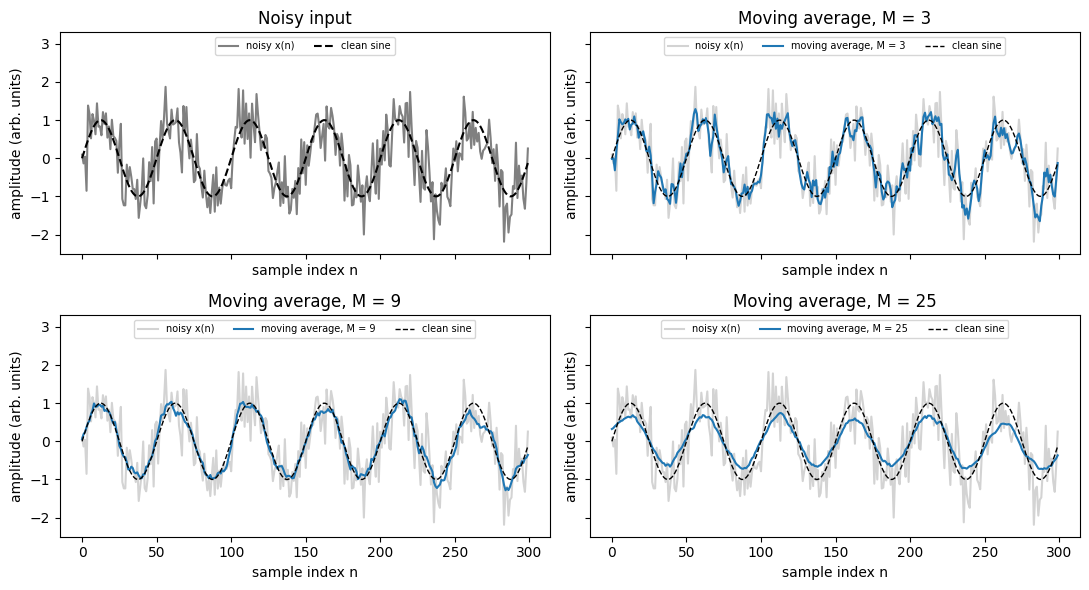

In [5]:
# Lab 1B - Task 3.2: smoothing a noisy sine with moving-average filters
rng = np.random.default_rng(2)
n = np.arange(300)                                  # sample index 0 ... 299
clean = np.sin(2*np.pi*n/50)                        # the signal we want (period 50 samples)
x = clean + 0.5*rng.standard_normal(300)            # add Gaussian noise w(n), scaled by 0.5

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
axes = axes.ravel()

axes[0].plot(n, x, color="gray", label="noisy x(n)")
axes[0].plot(n, clean, "k--", label="clean sine")
axes[0].set_title("Noisy input")

for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M) / M                              # moving-average filter: M equal weights 1/M
    y = np.convolve(x, h, mode="same")              # smooth; "same" keeps the original length
    ax.plot(n, x, color="lightgray", label="noisy x(n)")
    ax.plot(n, y, label=f"moving average, M = {M}")
    ax.plot(n, clean, "k--", linewidth=1, label="clean sine")
    ax.set_title(f"Moving average, M = {M}")

for ax in axes:
    ax.set_xlabel("sample index n")
    ax.set_ylabel("amplitude (arb. units)")
    ax.set_ylim(-2.5, 3.3)
    ax.legend(loc="upper center", ncol=3, fontsize=7)

plt.tight_layout()
plt.show()

In [6]:
# Lab 1B - Task 3.2 (measurement): noise reduction vs distortion
mid = slice(30, 270)          # ignore the edges, where the filter has too few neighbours
print(" M | noise RMS | sine amplitude kept")
for M in [1, 3, 9, 25]:       # M = 1 means no smoothing at all
    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")              # filter the noisy signal
    ideal = np.convolve(clean, h, mode="same")      # what the filter does to the clean sine alone
    noise_rms = np.std((y - ideal)[mid])            # what is left of the noise
    amp = np.max(np.abs(ideal[mid]))                # how much of the sine survives
    print(f"{M:2d} |   {noise_rms:.3f}    |   {amp:.3f}")

 M | noise RMS | sine amplitude kept
 1 |   0.501    |   0.998
 3 |   0.285    |   0.993
 9 |   0.144    |   0.946
25 |   0.076    |   0.636


**Task 3.2 observation.** A longer moving average removes more noise but distorts the wanted signal more. The noise level fell from 0.50 (no smoothing) to 0.29, 0.14 and 0.08 for M = 3, 9 and 25, roughly following 0.5/√M. But the sine was also weakened: it kept about 99% of its amplitude at M = 3, 95% at M = 9 and only 64% at M = 25, which is why the M = 25 curve sits clearly below the dashed clean sine. So M = 3 is still noisy, M = 9 is a good compromise, and M = 25 is very smooth but distorts the signal. The reason is that a moving average is a low-pass filter: the more samples it averages, the lower its cut-off frequency, until it starts to attenuate the 50-sample sine itself.

## Task 3.3 — Testing linearity and time-invariance numerically (Lab 1B)

In [7]:
# Lab 1B - Task 3.3: test linearity and time-invariance of three systems
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)   # two random test signals
a, b = 2.0, -3.0                                            # two constants

systems = {"x^2":            lambda x: x**2,
           "n x(n)":         lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}

for name, T in systems.items():
    # Linearity test: T(a*x1 + b*x2) must equal a*T(x1) + b*T(x2)
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    # Time-invariance test: delaying the input by 5 must just delay the output by 5
    xd = np.concatenate([np.zeros(5), x1])[:50]             # input delayed by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]          # output delayed by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Task 3.3 results and explanation.**

| System | Linear | Time-invariant |
|---|---|---|
| y(n) = x(n)² | No | Yes |
| y(n) = n·x(n) | Yes | No |
| Moving average (3 points) | Yes | Yes |

Definitions used: a system is **linear** if it obeys superposition, T[a·x₁ + b·x₂] = a·T[x₁] + b·T[x₂]. It is **time-invariant** if delaying the input by n₀ only delays the output by n₀.

- **x(n)²:** not linear, because squaring does not obey superposition: (a·x₁ + b·x₂)² = a²x₁² + 2ab·x₁x₂ + b²x₂², which has a cross-term and the wrong constants compared with a·x₁² + b·x₂². It is time-invariant because the rule "square the current sample" is the same at every time, so a delayed input gives a delayed output.
- **n·x(n):** linear, because multiplying each sample by a fixed number n is just scaling, so n(a·x₁ + b·x₂) = a·n·x₁ + b·n·x₂. It is not time-invariant, because the multiplier n changes with time: the delayed input gives n·x(n − 5), but the delayed output is (n − 5)·x(n − 5). This matches my pre-lab test.
- **Moving average:** linear and time-invariant, so it is an LTI system. Each output is a weighted sum of the current and past samples with fixed weights (1/3, 1/3, 1/3), which is a convolution with h(n) = {1/3, 1/3, 1/3}.

## Task 3.4 — Finding a hidden delay with cross-correlation (Lab 1B)

estimated delay: 37 samples
in time: 37.0 ms
distance at 343 m/s: 12.69 m


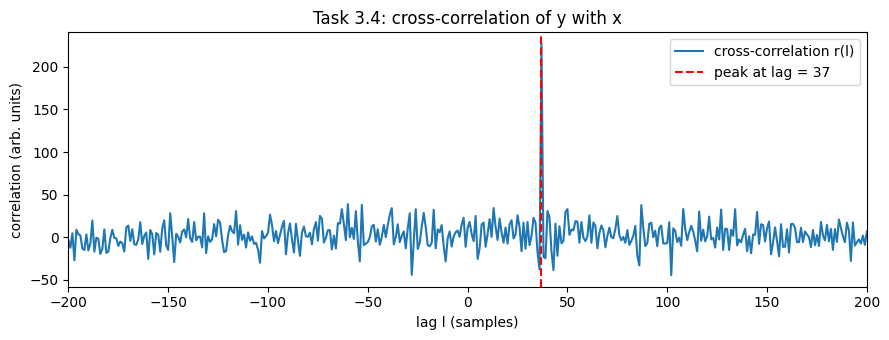

In [8]:
# Lab 1B - Task 3.4 (part 1): estimate a hidden delay with cross-correlation
rng = np.random.default_rng(1)
fs = 1000                                     # sampling rate: 1000 samples per second
x = rng.standard_normal(500)                  # the transmitted signal (random)
true_delay = 37                               # the delay we hide in the received signal
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)

r = signal.correlate(y, x, mode="full")                          # compare y with x at every shift
lags = signal.correlation_lags(len(y), len(x), mode="full")      # the shift value for each point of r
est = lags[np.argmax(r)]                                         # the shift where they match best

print("estimated delay:", est, "samples")
print(f"in time: {est/fs*1000:.1f} ms")
print(f"distance at 343 m/s: {343*est/fs:.2f} m")

plt.plot(lags, r, label="cross-correlation r(l)")
plt.axvline(est, color="r", linestyle="--", label=f"peak at lag = {est}")
plt.xlim(-200, 200)
plt.xlabel("lag l (samples)")
plt.ylabel("correlation (arb. units)")
plt.title("Task 3.4: cross-correlation of y with x")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [9]:
# Lab 1B - Task 3.4 (part 2): when does the delay estimate fail as noise grows?
rng = np.random.default_rng(1)
x = rng.standard_normal(500)                  # transmitted signal
true_delay = 37
lags = signal.correlation_lags(500, 500, mode="full")
trials = 100                                  # repeat each noise level 100 times

print("noise std | estimate in run 1 | correct delay in 100 runs")
for sd in [0.5, 1, 2, 4, 8]:                  # noise standard deviations to test
    correct = 0
    for t in range(trials):
        noise = sd * rng.standard_normal(500)                  # a new noise draw each time
        y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise
        r = signal.correlate(y, x, mode="full")
        est = lags[np.argmax(r)]
        if t == 0:
            first = est                       # remember the first run's estimate
        if est == true_delay:
            correct += 1                      # count the runs that found the right delay
    print(f"{sd:9.1f} | {first:18d} | {correct:3d} / {trials}")

noise std | estimate in run 1 | correct delay in 100 runs
      0.5 |                 37 | 100 / 100
      1.0 |                 37 | 100 / 100
      2.0 |                 37 | 100 / 100
      4.0 |                 37 |  53 / 100
      8.0 |                132 |  10 / 100


**Task 3.4 observation.** Cross-correlating the received signal with the transmitted one gave a peak at a lag of 37 samples, which is the delay that was hidden in it. At fs = 1000 Hz this is 37 ms, and a sound pulse at 343 m/s travels 343 × 0.037 ≈ 12.69 m in that time. When I repeated the estimate 100 times at each noise level, it found the right delay in 100/100 runs for noise standard deviations of 0.5, 1 and 2, but only in 53/100 runs at 4 and 10/100 at 8. So the estimate starts to fail at a noise standard deviation of about 4, which is far larger than the signal amplitude of 0.6. It works for so long because the correlation adds up 500 products, so the random noise averages out while the real match adds up. A single run at noise 4 happened to give the correct delay, which shows that one run can hide the failure.

## Task 3.5 — Difference equation (Lab 1B)
System: y(n) − (3/4) y(n−1) + (1/8) y(n−2) = x(n) + x(n−1)

 n | recursion | lfilter  | closed form
 0 |  1.000000 | 1.000000 | 1.000000
 1 |  1.750000 | 1.750000 | 1.750000
 2 |  1.187500 | 1.187500 | 1.187500
 3 |  0.671875 | 0.671875 | 0.671875
 4 |  0.355469 | 0.355469 | 0.355469
 5 |  0.182617 | 0.182617 | 0.182617
 6 |  0.092529 | 0.092529 | 0.092529
 7 |  0.046570 | 0.046570 | 0.046570
 8 |  0.023361 | 0.023361 | 0.023361
 9 |  0.011700 | 0.011700 | 0.011700
all three match: True


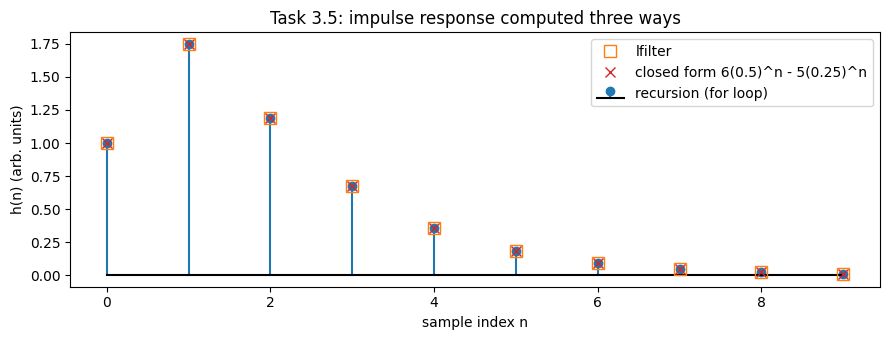

In [10]:
# Lab 1B - Task 3.5 (parts 1-3): impulse response h(n) computed three ways
N = 10
n = np.arange(N)
x_imp = np.zeros(N); x_imp[0] = 1                    # unit impulse: 1 at n = 0, zero elsewhere

# Part 1: direct recursion, y(n) = x(n) + x(n-1) + 0.75*y(n-1) - 0.125*y(n-2)
h_loop = np.zeros(N)
for k in range(N):
    xk  = x_imp[k]
    xk1 = x_imp[k-1] if k >= 1 else 0                # x(n-1), zero before the start
    y1  = h_loop[k-1] if k >= 1 else 0               # y(n-1), zero before the start
    y2  = h_loop[k-2] if k >= 2 else 0               # y(n-2), zero before the start
    h_loop[k] = xk + xk1 + 0.75*y1 - 0.125*y2

# Part 2: the same thing with scipy's lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], x_imp)

# Part 3: the closed formula from handout Example 2.5
h_cf = 6*(0.5)**n - 5*(0.25)**n

print(" n | recursion | lfilter  | closed form")
for k in range(N):
    print(f"{k:2d} | {h_loop[k]:9.6f} | {h_lf[k]:8.6f} | {h_cf[k]:8.6f}")
print("all three match:", np.allclose(h_loop, h_lf) and np.allclose(h_loop, h_cf))

plt.stem(n, h_loop, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="recursion (for loop)")
plt.plot(n, h_lf, "s", color="C1", markersize=9, markerfacecolor="none", label="lfilter")
plt.plot(n, h_cf, "x", color="C3", markersize=7, label="closed form 6(0.5)^n - 5(0.25)^n")
plt.xlabel("sample index n")
plt.ylabel("h(n) (arb. units)")
plt.title("Task 3.5: impulse response computed three ways")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

step response at n = 0, 1, 2, 3: [1.     2.75   3.9375 4.6094]
step response final value (n = 39): 5.3333
H(1) = sum(b)/sum(a) = 2/0.375 = 5.3333


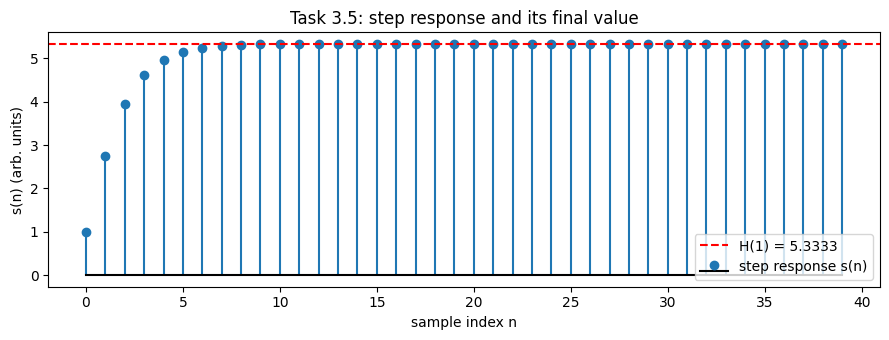

In [11]:
# Lab 1B - Task 3.5 (part 4): step response and its final value
b, a = [1, 1], [1, -0.75, 0.125]               # numerator and denominator coefficients
N2 = 40
n2 = np.arange(N2)
s = signal.lfilter(b, a, np.ones(N2))          # input = unit step (all ones)
H1 = np.sum(b) / np.sum(a)                     # H(1) = sum(b) / sum(a)

print(f"step response at n = 0, 1, 2, 3: {np.round(s[:4], 4)}")
print(f"step response final value (n = {N2-1}): {s[-1]:.4f}")
print(f"H(1) = sum(b)/sum(a) = {np.sum(b)}/{np.sum(a)} = {H1:.4f}")

plt.stem(n2, s, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="step response s(n)")
plt.axhline(H1, color="r", linestyle="--", label=f"H(1) = {H1:.4f}")
plt.xlabel("sample index n")
plt.ylabel("s(n) (arb. units)")
plt.title("Task 3.5: step response and its final value")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Task 3.5 result.** Solving y(n) − (3/4)y(n−1) + (1/8)y(n−2) = x(n) + x(n−1) three ways gave the same impulse response for 0 ≤ n ≤ 9: direct recursion with a for loop, `signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)`, and the closed form h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ (the first values are 1, 1.75, 1.1875, 0.6719, …, and `np.allclose` returned True). The step response computed with `lfilter` settled at 5.3333 after about 15 samples, which matches H(1) = Σb/Σa = 2/0.375 = 5.3333.

## Analysis questions (Lab 1B)

**Q1.** Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths L and M?

**Answer 1.** Both methods do the same amount of arithmetic: direct convolution needs L × M multiplications (for L = M = 2000 that is 4,000,000) and about L + M − 1 output samples. The difference is how the work is done. My loop is run by Python one step at a time, which is slow for every multiplication and addition, while np.convolve runs the same sum in compiled code. In Task 3.1 my loop took several seconds while np.convolve took only a few milliseconds, more than 1000 times faster, with the same result.

**Q2.** Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

**Answer 2.** Only the moving average is LTI. The system x(n)² is time-invariant but not linear, and n·x(n) is linear but not time-invariant. Yes, this can be predicted from the definitions: squaring is a non-linear operation (it creates the cross-term 2ab·x₁x₂), and multiplying by n uses a coefficient that changes with time, so shifting the input does not just shift the output. The moving average uses fixed weights on the current and past samples, which is a convolution, so it is linear and time-invariant.

**Q3.** Give two engineering applications of cross-correlation in Tanzania.

**Answer 3.** (1) *Locating leaks in water pipes:* sensors are placed on the pipe on each side of a suspected leak. The leak noise reaches the two sensors at slightly different times, and the peak of the cross-correlation gives that time difference, which together with the speed of sound in the pipe shows how far the leak is from the sensors. (2) *Radar or GPS ranging:* a radar (for example at an airport) or a GPS receiver compares the signal it sent or expects with the one it receives. The lag of the correlation peak is the travel time, and distance = speed × time, the same idea as Task 3.4, where a 37-sample delay at 1000 Hz gave 12.69 m at 343 m/s.

**Q4.** Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.

**Answer 4.** It is **IIR**. The impulse response h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ never becomes exactly zero for n ≥ 0; it only gets smaller and smaller (the recursion uses feedback from past outputs), so its length is infinite. It is **stable** (BIBO), because the impulse response is absolutely summable: all h(n) are positive, so Σ|h(n)| = Σh(n) = 6/(1 − 0.5) − 5/(1 − 0.25) = 12 − 6.67 = 5.33, a finite number, which equals H(1) found in Task 3.5. The same follows from the decaying terms (0.5)ⁿ and (0.25)ⁿ, whose bases are smaller than 1.

## AI-use statement

- **Tool:** Claude (Anthropic).
- **Used for:** step-by-step guidance on setting up and running this lab in Google Colab, the code for Tasks 3.1–3.5, explanations of what each part of the code does, and first drafts of the pre-lab answers, the observation written after each task, and the answers to the analysis questions.
- **How I verified it:** I ran every cell myself and checked the results against the theory: my pre-lab convolution answer matched both my own `conv` function and `np.convolve`; the three ways of computing the impulse response in Task 3.5 agreed (`np.allclose` returned True); the final value of the step response matched H(1) = Σb/Σa; and the results of Task 3.3 matched the definitions of linearity and time-invariance.